# 01 · Business Context, Data Quality and EDA

The IEEE-CIS dataset represents online payment transactions with a rare fraud outcome.
The operational objective is to prioritize manual review within a daily capacity of 1% of transactions.
This analysis examines data integrity, missingness, class imbalance and temporal variation before modeling.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src" / "fraud_detection").is_dir()
)
sys.path.insert(0, str(ROOT / "src"))

In [2]:
from fraud_detection.config import Config
from fraud_detection.data import ID, TARGET, TIME

config = Config.load(ROOT / "configs" / "default.yaml")
processed_dir = Path(config.processed_dir)
artifact_dir = Path(config.output_dir)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.2})

In [3]:
%matplotlib inline

## 1. Business Objective

The decision space consists of approval and manual review. Expected cost combines a $100 loss per missed fraud,
a $1 review cost and an assumed review sensitivity of 80%. Automatic blocking is outside the decision policy,
so false-blocking costs do not enter the calculation. Ranking quality and probability calibration serve
different roles in this capacity-constrained setting.

In [4]:
display(
    pd.Series(
        {
            "daily_review_capacity": config.review_rate,
            "loss_per_missed_fraud_usd": config.fraud_loss,
            "cost_per_review_usd": config.review_cost,
            "review_sensitivity": config.review_sensitivity,
        },
        name="business_assumptions",
    )
)

daily_review_capacity          0.01
loss_per_missed_fraud_usd    100.00
cost_per_review_usd            1.00
review_sensitivity             0.80
Name: business_assumptions, dtype: float64

## 2. Data Sources and Schema Consistency

Transactions form the primary table, with identity attributes joined one-to-one on TransactionID.
Test identity names use hyphens instead of underscores; normalization aligns both schemas.
Source hashes establish provenance, while validation checks transaction keys, labels, timestamps and amounts.

In [5]:
manifest = json.loads((processed_dir / "manifest.json").read_text())
display(pd.DataFrame(manifest["datasets"]).T)
display(pd.DataFrame(manifest["files"])[["file", "bytes", "sha256"]])

,rows,columns
train,590540,434
test,506691,433


,file,bytes,sha256
0,train_transaction.csv,683351067,3a5c83ab6b3cc13dcabe5ffa9f522307fd5f7f7b6e6f6a...
1,train_identity.csv,26529680,b63c725d8377be90a995268d97f347c17d456b95db4580...
2,test_transaction.csv,613194934,2a8e51f1d335a86025d2b7f45beb9b78d0ab1edd726ef5...
3,test_identity.csv,25797161,3e5978cb13ca5e72f52babc4349ae0125e14b87ca8bfab...


In [6]:
from fraud_detection.data import normalize_columns, validate_transactions

train_header = pd.read_csv(Path(config.raw_dir) / "train_identity.csv", nrows=0).columns
test_header = pd.read_csv(Path(config.raw_dir) / "test_identity.csv", nrows=0).columns
schema = pd.DataFrame(
    {
        "train": train_header,
        "test_raw": test_header,
        "test_normalized": normalize_columns(test_header),
    }
)
assert schema.train.tolist() == schema.test_normalized.tolist()
display(schema.head(12))

columns = [ID, TARGET, TIME, "TransactionAmt", "ProductCD", "card4", "P_emaildomain"]
transactions = pd.read_parquet(processed_dir / "train.parquet", columns=columns)
validate_transactions(transactions, labeled=True)
display(transactions.head())

,train,test_raw,test_normalized
0,TransactionID,TransactionID,TransactionID
1,id_01,id-01,id_01
2,id_02,id-02,id_02
3,id_03,id-03,id_03
4,id_04,id-04,id_04
5,id_05,id-05,id_05
6,id_06,id-06,id_06
7,id_07,id-07,id_07
8,id_08,id-08,id_08
9,id_09,id-09,id_09


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card4,P_emaildomain
0,2987000,0.0,86400,68.5,W,discover,<NA>
1,2987001,0.0,86401,29.0,W,mastercard,gmail.com
2,2987002,0.0,86469,59.0,W,visa,outlook.com
3,2987003,0.0,86499,50.0,W,mastercard,yahoo.com
4,2987004,0.0,86506,50.0,H,mastercard,gmail.com


## 3. Missingness and Data Quality

Identity coverage is partial, and several V/D attributes exhibit substantial missingness.
Complete-case deletion would discard a large share of transactions. Numeric missing values remain available
to LightGBM, categorical missingness receives an explicit token, and constant-feature removal is fitted
within the training partition.

,value
rows,590540.000000
columns,434.000000
fraud_count,20663.000000
fraud_rate,0.034990
duplicate_ids,0.000000
missing_cells_rate,0.450744


,feature,dtype,missing_rate,unique_values
417,id_24,float32,0.991962,12
418,id_25,float32,0.991310,341
400,id_07,float32,0.991271,84
401,id_08,float32,0.991271,94
414,id_21,float32,0.991264,490
419,id_26,float32,0.991257,95
420,id_27,string,0.991247,2
416,id_23,string,0.991247,3
415,id_22,float32,0.991247,25
14,dist2,float32,0.936284,1751


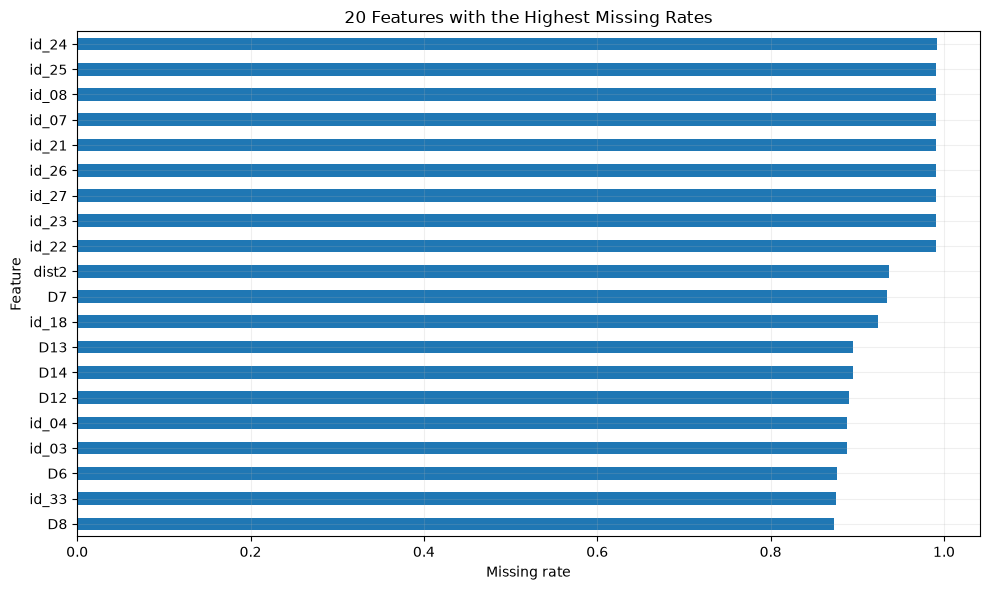

In [7]:
summary = json.loads((artifact_dir / "eda" / "summary.json").read_text())
display(
    pd.Series(
        {
            key: summary[key]
            for key in [
                "rows",
                "columns",
                "fraud_count",
                "fraud_rate",
                "duplicate_ids",
                "missing_cells_rate",
            ]
        }
    ).to_frame("value")
)
profile = pd.read_csv(artifact_dir / "eda" / "feature_profile.csv")
display(profile.sort_values("missing_rate", ascending=False).head(20))

fig, ax = plt.subplots(figsize=(10, 6))
profile.nlargest(20, "missing_rate").sort_values("missing_rate").plot.barh(
    x="feature",
    y="missing_rate",
    legend=False,
    ax=ax,
)
ax.set(title="20 Features with the Highest Missing Rates", xlabel="Missing rate", ylabel="Feature")
plt.tight_layout()
plt.show()

## 4. Class Imbalance

Fraud represents a small fraction of transactions. Accuracy is dominated by legitimate payments,
whereas average precision measures ranking performance relative to fraud prevalence.
Resampling before temporal partitioning would compromise the evaluation design.

,rows,share
isFraud,,
0.0,569877,0.96501
1.0,20663,0.03499


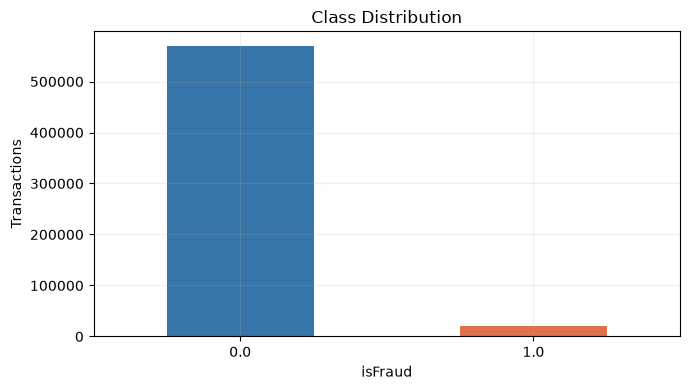

In [8]:
classes = transactions[TARGET].value_counts().sort_index().rename_axis("isFraud").to_frame("rows")
classes["share"] = classes.rows / classes.rows.sum()
display(classes)
fig, ax = plt.subplots(figsize=(7, 4))
classes.rows.plot.bar(ax=ax, rot=0, color=["#3675a9", "#df7248"])
ax.set(title="Class Distribution", ylabel="Transactions", xlabel="isFraud")
plt.tight_layout()
plt.show()

## 5. Temporal Variation

TransactionDT records elapsed seconds without a known calendar origin or timezone.
Relative days support a chronological evaluation, while daily volume and fraud-rate variation
describe the distribution changes a model encounters in later periods.

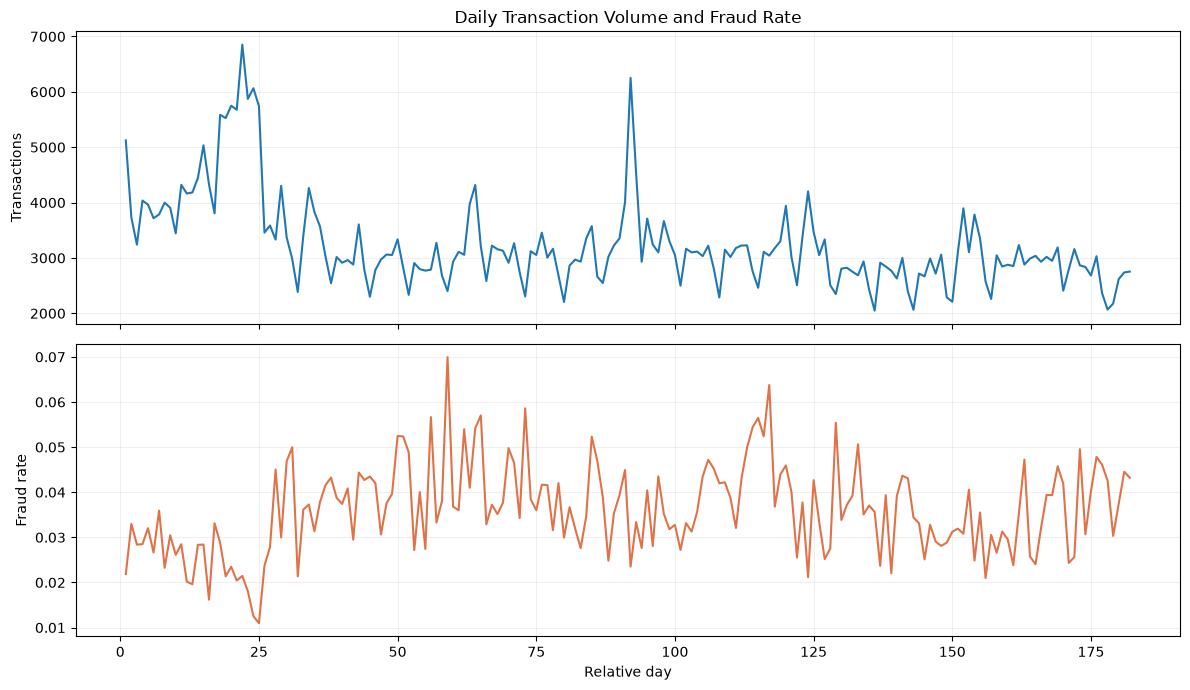

,day,transactions,fraud_count,fraud_rate,amount
0,1,5122,112.0,0.021866,742186.931
1,2,3730,123.0,0.032976,453400.013
2,3,3241,92.0,0.028386,348517.434
3,4,4036,115.0,0.028494,515968.997
4,5,3964,127.0,0.032038,543140.641


In [9]:
daily = pd.read_csv(artifact_dir / "eda" / "daily_data.csv")
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
daily.plot(x="day", y="transactions", ax=axes[0], legend=False)
daily.plot(x="day", y="fraud_rate", ax=axes[1], legend=False, color="#df7248")
axes[0].set(ylabel="Transactions", title="Daily Transaction Volume and Fraud Rate")
axes[1].set(xlabel="Relative day", ylabel="Fraud rate")
plt.tight_layout()
plt.show()
display(daily.head())

## 6. Transaction Amounts and Group Profiles

Transaction amounts have a long right tail, making quantiles and log-transformed distributions useful summaries.
Product and email-domain fraud rates describe differences between observed groups.
These full-period label summaries are excluded from model features.

,amount
0.00,0.251
0.25,43.321
0.50,68.769
0.75,125.000
0.95,445.000
0.99,1104.000
1.00,31937.391


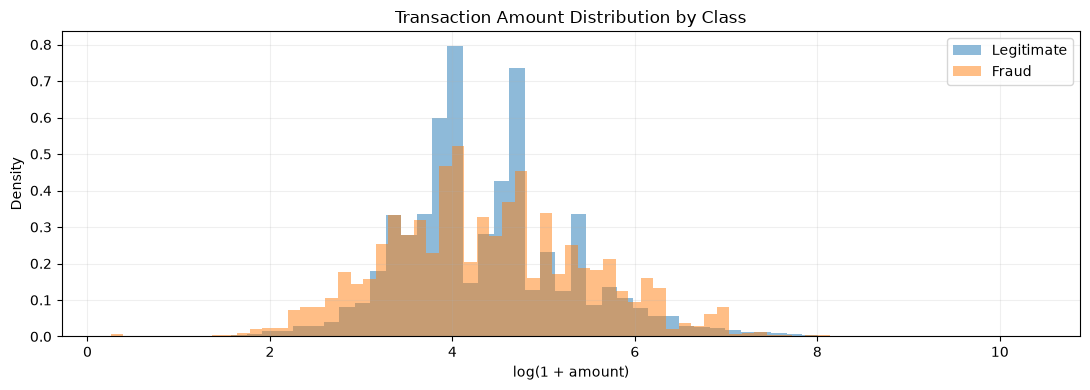

,transactions,fraud_rate,median_amount
ProductCD,,,
C,68519,0.116873,31.191
S,11628,0.058996,35.000
H,33024,0.047662,50.000
R,37699,0.037826,125.000
W,439670,0.020399,78.500


,transactions,fraud_rate
P_emaildomain,,
gmail.com,228355,0.043542
yahoo.com,100934,0.022757
<NA>,94456,0.029538
hotmail.com,45250,0.052950
anonymous.com,36998,0.023217
aol.com,28289,0.021811
comcast.net,7888,0.031187
icloud.com,6267,0.031434
outlook.com,5096,0.094584


In [10]:
display(
    transactions.TransactionAmt.quantile([0, 0.25, 0.5, 0.75, 0.95, 0.99, 1]).to_frame("amount")
)
fig, ax = plt.subplots()
for label, name in [(0, "Legitimate"), (1, "Fraud")]:
    amounts = transactions.loc[transactions[TARGET] == label, "TransactionAmt"]
    ax.hist(np.log1p(amounts), bins=60, density=True, alpha=0.5, label=name)
ax.set(title="Transaction Amount Distribution by Class", xlabel="log(1 + amount)", ylabel="Density")
ax.legend()
plt.tight_layout()
plt.show()

product = transactions.groupby("ProductCD", dropna=False).agg(
    transactions=(ID, "size"),
    fraud_rate=(TARGET, "mean"),
    median_amount=("TransactionAmt", "median"),
)
display(product.sort_values("fraud_rate", ascending=False))
email = transactions.groupby("P_emaildomain", dropna=False).agg(
    transactions=(ID, "size"),
    fraud_rate=(TARGET, "mean"),
)
display(email.nlargest(10, "transactions"))

## Analytical Findings

Partial identity coverage and widespread missingness favor explicit missing-value handling over row deletion.
Rare positive labels require ranking and review metrics alongside probability-quality measures.
Temporal changes motivate separate tuning, calibration and final evaluation periods.
The anonymized C/D/V attributes still require confirmation of their availability at decision time.